In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard[1].csv")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nClass Distribution:")
print(df["Class"].value_counts())

print("\nFraud Percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Dataset Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

    

In [2]:
# Remove duplicate transactions
df = df.drop_duplicates().copy()

# Handle missing values in numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

print("Cleaned Shape:", df.shape)
print(df.isnull().sum().sum())

Cleaned Shape: (283726, 31)
0


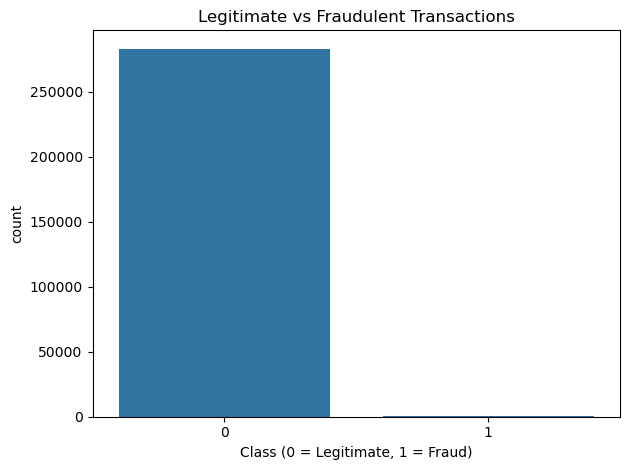

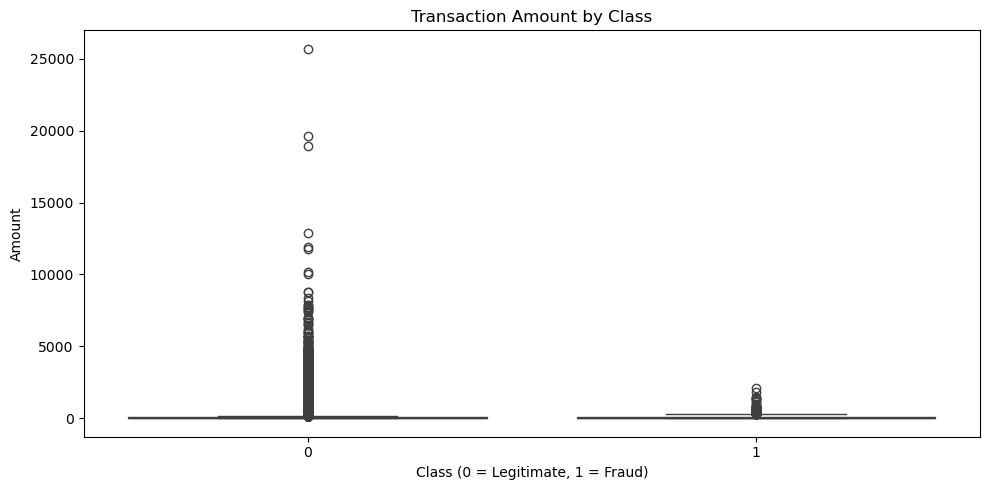


Fraud Rate by Transaction Amount Range:
Amount_Range
0-10       0.238427
10-50      0.060890
50-100     0.147933
100-500    0.192430
500+       0.373257
Name: Class, dtype: float64


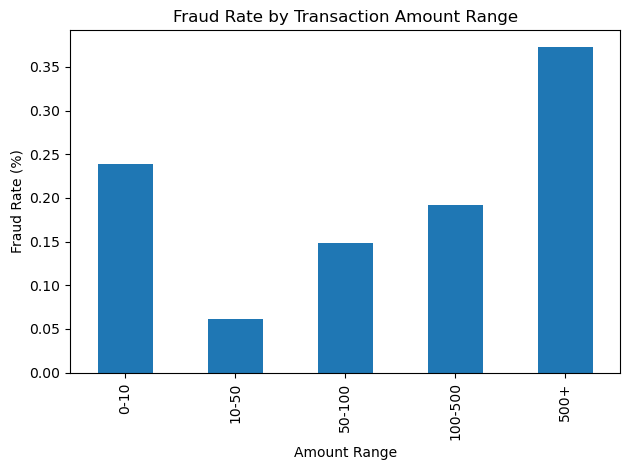

In [3]:
# Fraud vs legitimate transactions
sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.tight_layout()
plt.savefig("fraud_distribution.png")
plt.show()

# Transaction amount distribution
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.tight_layout()
plt.savefig("transaction_amount.png")
plt.show()

# Fraud rate by transaction amount range
df["Amount_Range"] = pd.cut(
    df["Amount"],
    bins=[-0.01, 10, 50, 100, 500, float("inf")],
    labels=["0-10", "10-50", "50-100", "100-500", "500+"]
)

fraud_rate = df.groupby(
    "Amount_Range",
    observed=False
)["Class"].mean() * 100

print("\nFraud Rate by Transaction Amount Range:")
print(fraud_rate)

fraud_rate.plot(kind="bar")
plt.title("Fraud Rate by Transaction Amount Range")
plt.xlabel("Amount Range")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.savefig("fraud_rate_by_amount.png")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)
from sklearn.base import clone
import joblib

X = df.drop(columns=["Class", "Amount_Range"], errors="ignore")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (226980, 30)
Testing data: (56746, 30)



Model: Logistic Regression
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

ROC-AUC: 0.9657
Average Precision: 0.6719


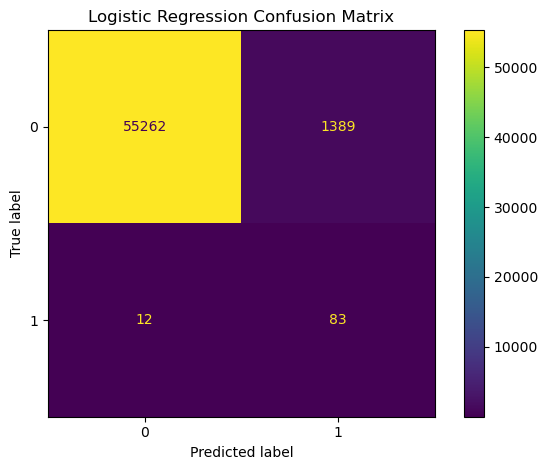


Model: Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746

ROC-AUC: 0.9444
Average Precision: 0.8061


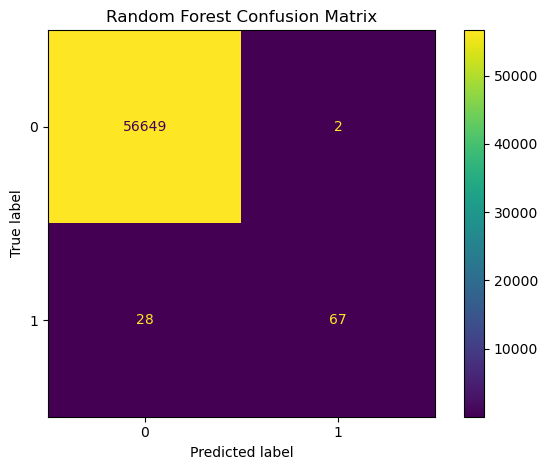


Model Comparison:
                 Model  Precision    Recall  F1 Score   ROC-AUC  \
0  Logistic Regression   0.056386  0.873684  0.105935  0.965655   
1        Random Forest   0.971014  0.705263  0.817073  0.944373   

   Average Precision  
0           0.671924  
1           0.806084  


In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced_subsample",
            n_jobs=-1
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test, probabilities
    )

    pr_auc = average_precision_score(
        y_test, probabilities
    )

    print("\nModel:", name)
    print(classification_report(
        y_test, predictions, zero_division=0
    ))
    print("ROC-AUC:", round(roc_auc, 4))
    print("Average Precision:", round(pr_auc, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions
    )
    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        name.replace(" ", "_") + "_confusion.png"
    )
    plt.show()

    results.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "Average Precision": pr_auc
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df)

results_df.to_csv(
    "fraud_model_comparison.csv", index=False
)

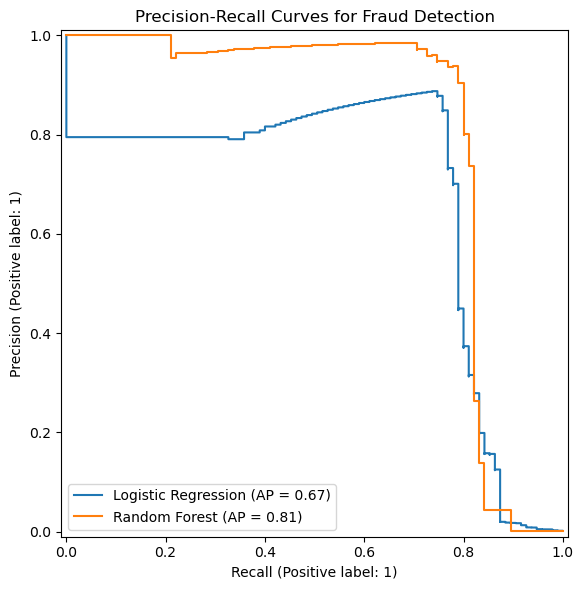

In [7]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curves for Fraud Detection")
plt.tight_layout()
plt.savefig("precision_recall_curve.png")
plt.show()

In [8]:
from sklearn.metrics import confusion_matrix

# Select Random Forest for further analysis
selected_model = trained_models["Random Forest"]

predictions = selected_model.predict(X_test)

cm = confusion_matrix(y_test, predictions)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nInterpretation:")
print("False positives: Legitimate transactions flagged as fraud.")
print("False negatives: Fraudulent transactions missed by the model.")

True Negatives: 56649
False Positives: 2
False Negatives: 28
True Positives: 67

Interpretation:
False positives: Legitimate transactions flagged as fraud.
False negatives: Fraudulent transactions missed by the model.
